# Company Insights 360°

### End-to-End Business Analytics Project

**Tech Stack:** Python | SQL | Power BI

---

## Project Objective

The objective of this project is to analyze company data and generate meaningful business insights using Python, SQL, and Power BI.

The analysis will focus on:

- Customer behavior
- Sales and revenue performance
- Product and category performance
- Customer journey and conversion
- Returns and return reasons
- Marketing campaign performance
- Payment methods
- Business KPIs

## 1. Import Required Libraries

In [198]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

In [199]:
df = pd.read_csv("../data/Customer360Insights.csv")

In [200]:
df.head()

,SessionStart,CustomerID,FullName,Gender,Age,CreditScore,MonthlyIncome,Country,State,City,...,Price,Quantity,CampaignSchema,CartAdditionTime,OrderConfirmation,OrderConfirmationTime,PaymentMethod,SessionEnd,OrderReturn,ReturnReason
0,2019-01-01 02:42:00,1001,Brittany Franklin,Male,57,780,7591,China,Guangdong,Dongguan,...,50,4,Instagram-ads,2019-01-01 02:49:00,True,2019-01-01 03:02:00,Cash On Delivery,2019-01-01 02:53:00,False,NaN
1,2019-01-02 20:35:00,1002,Scott Stewart,Female,69,746,3912,China,Shandong,Yantai,...,80,6,Google-ads,2019-01-02 20:50:00,True,2019-01-02 20:58:00,Debit Card,2019-01-02 20:54:00,False,NaN
2,2019-01-04 03:11:00,1003,Elizabeth Fowler,Female,21,772,7460,UK,England,Birmingham,...,20,2,Facebook-ads,2019-01-04 03:30:00,True,2019-01-04 03:40:00,Cash On Delivery,2019-01-04 03:35:00,False,NaN
3,2019-01-05 09:01:00,1004,Julian Wall,Female,67,631,4765,UK,England,Birmingham,...,20,2,Twitter-ads,2019-01-05 09:17:00,True,2019-01-05 09:26:00,Cash On Delivery,2019-01-05 09:20:00,False,NaN
4,2019-01-05 13:35:00,1005,James Simmons,Male,57,630,3268,China,Shandong,Yantai,...,100,6,Billboard-QR code,2019-01-05 13:40:00,True,2019-01-05 13:52:00,Debit Card,2019-01-05 13:42:00,False,NaN


In [201]:
df.shape

(2000, 23)

## 3. Understanding the Dataset

In [202]:
df.columns

Index(['SessionStart', 'CustomerID', 'FullName', 'Gender', 'Age',
       'CreditScore', 'MonthlyIncome', 'Country', 'State', 'City', 'Category',
       'Product', 'Cost', 'Price', 'Quantity', 'CampaignSchema ',
       'CartAdditionTime', 'OrderConfirmation', 'OrderConfirmationTime',
       'PaymentMethod', 'SessionEnd', 'OrderReturn', 'ReturnReason'],
      dtype='str')

In [203]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   SessionStart           2000 non-null   str   
 1   CustomerID             2000 non-null   int64 
 2   FullName               2000 non-null   str   
 3   Gender                 2000 non-null   str   
 4   Age                    2000 non-null   int64 
 5   CreditScore            2000 non-null   int64 
 6   MonthlyIncome          2000 non-null   int64 
 7   Country                2000 non-null   str   
 8   State                  2000 non-null   str   
 9   City                   2000 non-null   str   
 10  Category               2000 non-null   str   
 11  Product                2000 non-null   str   
 12  Cost                   2000 non-null   int64 
 13  Price                  2000 non-null   int64 
 14  Quantity               2000 non-null   int64 
 15  CampaignSchema         2000 non-

In [204]:
df.describe()

,CustomerID,Age,CreditScore,MonthlyIncome,Cost,Price,Quantity
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1609.064000,44.487500,690.126500,5589.697000,135.816000,210.921500,3.527500
std,349.835233,16.350367,50.618066,1441.584931,261.935533,394.196811,1.697847
min,1001.000000,18.000000,600.000000,3001.000000,5.000000,8.000000,1.000000
25%,1311.000000,31.000000,646.000000,4403.500000,15.000000,25.000000,2.000000
50%,1610.000000,44.000000,691.000000,5656.500000,30.000000,50.000000,3.000000
75%,1915.250000,59.000000,732.000000,6856.250000,60.000000,100.000000,5.000000
max,2200.000000,72.000000,780.000000,7999.000000,1000.000000,1500.000000,6.000000


In [205]:
df.nunique()

SessionStart             2000
CustomerID               1200
FullName                 1200
Gender                      2
Age                        55
CreditScore               180
MonthlyIncome            1069
Country                     9
State                      18
City                       52
Category                    5
Product                    20
Cost                       15
Price                      17
Quantity                    6
CampaignSchema              6
CartAdditionTime         2000
OrderConfirmation           2
OrderConfirmationTime    1700
PaymentMethod               4
SessionEnd               1999
OrderReturn                 2
ReturnReason                5
dtype: int64

### Initial Observations

The above analysis helps us understand:

- Number of records and features
- Available columns
- Data types
- Numerical data distribution
- Number of unique values in each column

## 4. Data Quality Check

### 4.1 Checking Missing Values

In [206]:
df.isnull().sum()

SessionStart                0
CustomerID                  0
FullName                    0
Gender                      0
Age                         0
CreditScore                 0
MonthlyIncome               0
Country                     0
State                       0
City                        0
Category                    0
Product                     0
Cost                        0
Price                       0
Quantity                    0
CampaignSchema              0
CartAdditionTime            0
OrderConfirmation           0
OrderConfirmationTime     300
PaymentMethod             300
SessionEnd                  0
OrderReturn               300
ReturnReason             1764
dtype: int64

In [207]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
missing_values

ReturnReason             1764
OrderConfirmationTime     300
PaymentMethod             300
OrderReturn               300
dtype: int64

### 4.2 Checking Duplicate Records

In [208]:
df.duplicated().sum()

np.int64(0)

### 4.3 Checking Unique Values

In [209]:
df.nunique().sort_values(ascending=False)

SessionStart             2000
CartAdditionTime         2000
SessionEnd               1999
OrderConfirmationTime    1700
CustomerID               1200
FullName                 1200
MonthlyIncome            1069
CreditScore               180
Age                        55
City                       52
Product                    20
State                      18
Price                      17
Cost                       15
Country                     9
CampaignSchema              6
Quantity                    6
ReturnReason                5
Category                    5
PaymentMethod               4
Gender                      2
OrderConfirmation           2
OrderReturn                 2
dtype: int64

### Initial Data Quality Observation

We will use the missing-value, duplicate, and unique-value analysis to determine which columns require cleaning before performing further analysis.

## 5. Data Type Validation

In [210]:
df.dtypes

SessionStart                str
CustomerID                int64
FullName                    str
Gender                      str
Age                       int64
CreditScore               int64
MonthlyIncome             int64
Country                     str
State                       str
City                        str
Category                    str
Product                     str
Cost                      int64
Price                     int64
Quantity                  int64
CampaignSchema              str
CartAdditionTime            str
OrderConfirmation          bool
OrderConfirmationTime       str
PaymentMethod               str
SessionEnd                  str
OrderReturn              object
ReturnReason                str
dtype: object

In [211]:
df.select_dtypes(include="object").columns

C:\Users\KIIT\AppData\Local\Temp\ipykernel_20728\1196084386.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['SessionStart', 'FullName', 'Gender', 'Country', 'State', 'City',
       'Category', 'Product', 'CampaignSchema ', 'CartAdditionTime',
       'OrderConfirmationTime', 'PaymentMethod', 'SessionEnd', 'OrderReturn',
       'ReturnReason'],
      dtype='str')

In [212]:
df.select_dtypes(include=np.number).columns

Index(['CustomerID', 'Age', 'CreditScore', 'MonthlyIncome', 'Cost', 'Price',
       'Quantity'],
      dtype='str')

### Date and Time Columns

Date/time columns need to be converted into proper datetime format before performing time-based analysis.

In [213]:
date_time_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in ["date", "time", "start", "end"])
]

date_time_columns

['SessionStart',
 'Gender',
 'CartAdditionTime',
 'OrderConfirmationTime',
 'SessionEnd']

## 6. Data Cleaning

### 6.1 Remove Duplicate Records

In [214]:
df.duplicated().sum()

np.int64(0)

In [215]:
df = df.drop_duplicates().copy()

In [216]:
df.duplicated().sum()

np.int64(0)

### 6.2 Standardize Text Columns

In [217]:
text_columns = df.select_dtypes(include=["object"]).columns

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

C:\Users\KIIT\AppData\Local\Temp\ipykernel_20728\612852665.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=["object"]).columns


In [218]:
df.head()
df.dtypes

SessionStart                str
CustomerID                int64
FullName                    str
Gender                      str
Age                       int64
CreditScore               int64
MonthlyIncome             int64
Country                     str
State                       str
City                        str
Category                    str
Product                     str
Cost                      int64
Price                     int64
Quantity                  int64
CampaignSchema              str
CartAdditionTime            str
OrderConfirmation          bool
OrderConfirmationTime       str
PaymentMethod               str
SessionEnd                  str
OrderReturn              object
ReturnReason                str
dtype: object

### 6.3 Convert Date and Time Columns

In [219]:
for col in date_time_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

C:\Users\KIIT\AppData\Local\Temp\ipykernel_20728\2542940107.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


In [220]:
df[date_time_columns].dtypes

SessionStart             datetime64[us]
Gender                    datetime64[s]
CartAdditionTime         datetime64[us]
OrderConfirmationTime    datetime64[us]
SessionEnd               datetime64[us]
dtype: object

### 6.4 Check Missing Values After Cleaning

In [221]:
df.isnull().sum()

SessionStart                0
CustomerID                  0
FullName                    0
Gender                   2000
Age                         0
CreditScore                 0
MonthlyIncome               0
Country                     0
State                       0
City                        0
Category                    0
Product                     0
Cost                        0
Price                       0
Quantity                    0
CampaignSchema              0
CartAdditionTime            0
OrderConfirmation           0
OrderConfirmationTime     300
PaymentMethod             300
SessionEnd                  0
OrderReturn               300
ReturnReason             1764
dtype: int64

## 6.5 Handling Missing Values

In [222]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

Gender                   2000
ReturnReason             1764
OrderConfirmationTime     300
PaymentMethod             300
OrderReturn               300
dtype: int64

In [223]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

missing_percentage

Gender                   100.0
ReturnReason              88.2
OrderConfirmationTime     15.0
PaymentMethod             15.0
OrderReturn               15.0
dtype: float64

### Missing Value Strategy

Missing values will be handled according to the meaning of each column.

- Numerical columns: investigate before imputing.
- Categorical columns: investigate before filling.
- Return-related fields: missing values may represent that an order was not returned.
- Date/time fields: investigate invalid or missing timestamps before removing records.

### 6.6 Checking Invalid Numerical Values

In [224]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


CustomerID
Minimum: 1001
Maximum: 2200

Age
Minimum: 18
Maximum: 72

CreditScore
Minimum: 600
Maximum: 780

MonthlyIncome
Minimum: 3001
Maximum: 7999

Cost
Minimum: 5
Maximum: 1000

Price
Minimum: 8
Maximum: 1500

Quantity
Minimum: 1
Maximum: 6


### 6.7 Checking Numerical Outliers

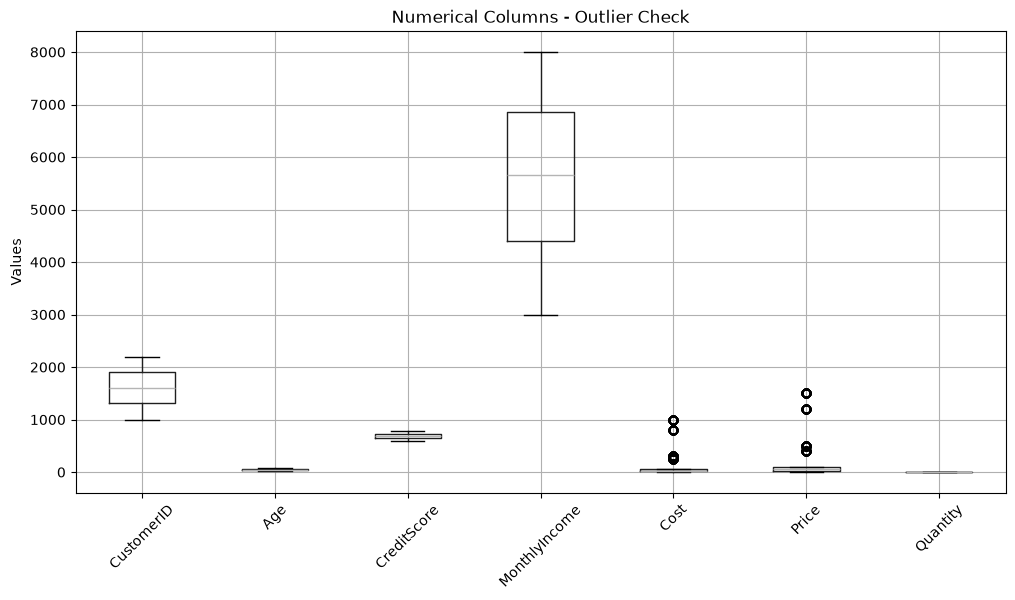

In [225]:
plt.figure(figsize=(12, 6))

df[numeric_columns].boxplot()

plt.xticks(rotation=45)
plt.title("Numerical Columns - Outlier Check")
plt.ylabel("Values")
plt.show()

## 7. Feature Engineering

Feature engineering is the process of creating new meaningful variables from existing data to support business analysis and generate useful insights.

### 7.1 Financial Metrics

We will calculate Revenue, Total Cost, Profit, and Profit Margin.

In [226]:
# Revenue
df["Revenue"] = df["Price"] * df["Quantity"]

# Total Cost
df["TotalCost"] = df["Cost"] * df["Quantity"]

# Profit
df["Profit"] = df["Revenue"] - df["TotalCost"]

# Profit Margin
df["ProfitMargin"] = np.where(
    df["Revenue"] != 0,
    (df["Profit"] / df["Revenue"]) * 100,
    0
)

In [227]:
df[
    [
        "Cost",
        "Price",
        "Quantity",
        "Revenue",
        "TotalCost",
        "Profit",
        "ProfitMargin"
    ]
].head()

,Cost,Price,Quantity,Revenue,TotalCost,Profit,ProfitMargin
0,30,50,4,200,120,80,40.0
1,50,80,6,480,300,180,37.5
2,12,20,2,40,24,16,40.0
3,12,20,2,40,24,16,40.0
4,60,100,6,600,360,240,40.0


### 7.2 Customer Segmentation

Customers will be grouped based on Age, Monthly Income, and Credit Score.

In [228]:
# Age Group
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 55, 65, np.inf],
    labels=[
        "Under 18",
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ],
    include_lowest=True
)

In [229]:
# Income Group
df["IncomeGroup"] = pd.qcut(
    df["MonthlyIncome"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

In [230]:
# Credit Score Group
df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=[0, 579, 669, 739, 799, 850],
    labels=[
        "Poor",
        "Fair",
        "Good",
        "Very Good",
        "Excellent"
    ],
    include_lowest=True
)

In [231]:
df[
    [
        "Age",
        "AgeGroup",
        "MonthlyIncome",
        "IncomeGroup",
        "CreditScore",
        "CreditScoreGroup"
    ]
].head(10)

,Age,AgeGroup,MonthlyIncome,IncomeGroup,CreditScore,CreditScoreGroup
0,57,56-65,7591,Very High,780,Very Good
1,69,65+,3912,Low,746,Very Good
2,21,18-25,7460,Very High,772,Very Good
3,67,65+,4765,Medium,631,Fair
4,57,56-65,3268,Low,630,Fair
5,36,36-45,5350,Medium,660,Fair
6,47,46-55,3972,Low,606,Fair
7,45,36-45,7455,Very High,627,Fair
8,59,56-65,3003,Low,609,Fair
9,25,18-25,4722,Medium,755,Very Good


### 7.3 Return Analysis

A binary ReturnFlag will be created to identify returned orders.

In [232]:
df["ReturnFlag"] = df["OrderReturn"].map({
    True: 1,
    False: 0
})

In [233]:
df["ReturnFlag"].value_counts(dropna=False)

ReturnFlag
0.0    1464
NaN     300
1.0     236
Name: count, dtype: int64

### 7.4 Customer Journey Features

The customer journey is analyzed from session start to cart addition, order confirmation, and session end.

In [234]:
# Session Duration
df["SessionDurationMinutes"] = (
    df["SessionEnd"] - df["SessionStart"]
).dt.total_seconds() / 60

In [235]:
# Time taken from cart addition to order confirmation
df["CartToOrderMinutes"] = (
    df["OrderConfirmationTime"] - df["CartAdditionTime"]
).dt.total_seconds() / 60

In [236]:
# Order conversion flag
df["OrderFlag"] = df["OrderConfirmation"].astype(int)

In [237]:
df[
    [
        "SessionDurationMinutes",
        "CartToOrderMinutes",
        "OrderFlag"
    ]
].head(10)

,SessionDurationMinutes,CartToOrderMinutes,OrderFlag
0,11.0,13.0,1
1,19.0,8.0,1
2,24.0,10.0,1
3,19.0,9.0,1
4,7.0,12.0,1
5,20.0,10.0,1
6,19.0,13.0,1
7,10.0,15.0,1
8,23.0,11.0,1
9,32.0,NaN,0


### 7.5 Final Feature Engineering Check

In [238]:
new_features = [
    "Revenue",
    "TotalCost",
    "Profit",
    "ProfitMargin",
    "AgeGroup",
    "IncomeGroup",
    "CreditScoreGroup",
    "ReturnFlag",
    "SessionDurationMinutes",
    "CartToOrderMinutes",
    "OrderFlag"
]

df[new_features].head()

,Revenue,TotalCost,Profit,ProfitMargin,AgeGroup,IncomeGroup,CreditScoreGroup,ReturnFlag,SessionDurationMinutes,CartToOrderMinutes,OrderFlag
0,200,120,80,40.0,56-65,Very High,Very Good,0.0,11.0,13.0,1
1,480,300,180,37.5,65+,Low,Very Good,0.0,19.0,8.0,1
2,40,24,16,40.0,18-25,Very High,Very Good,0.0,24.0,10.0,1
3,40,24,16,40.0,65+,Medium,Fair,0.0,19.0,9.0,1
4,600,360,240,40.0,56-65,Low,Fair,0.0,7.0,12.0,1


In [239]:
df.shape

(2000, 34)

## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand patterns, distributions, relationships, and trends in the dataset before building the final business dashboard.

### 8.1 Customer Analysis

#### 8.1.1 Age Distribution

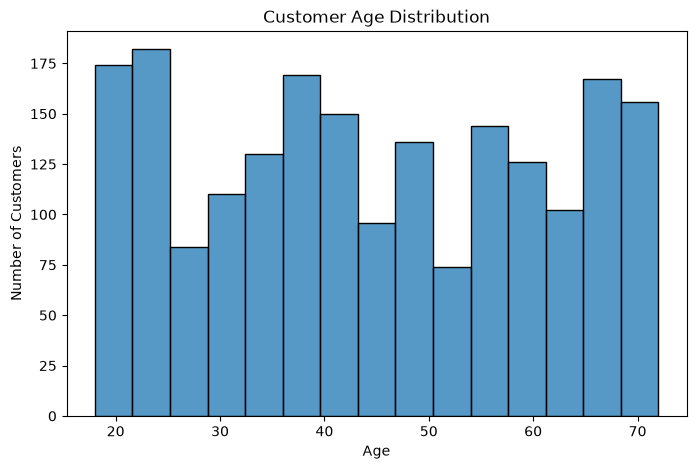

In [240]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=15)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

#### 8.1.2 Age Group Distribution

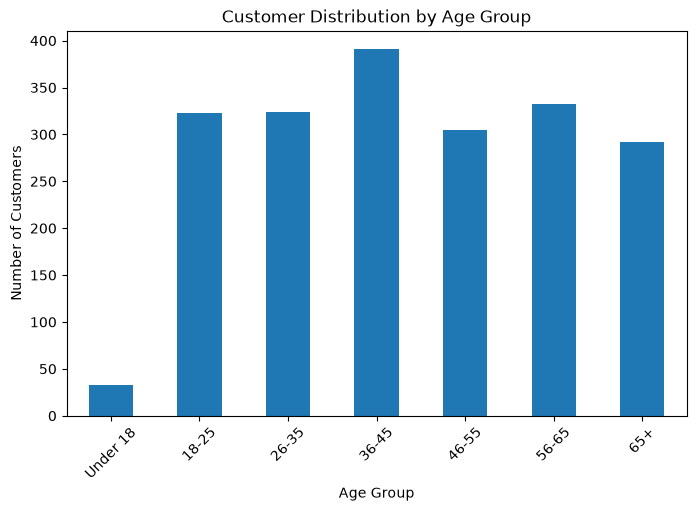

In [241]:
age_group_counts = df["AgeGroup"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

age_group_counts.plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)

plt.show()

#### 8.1.3 Gender Distribution

IndexError: index 0 is out of bounds for axis 0 with size 0

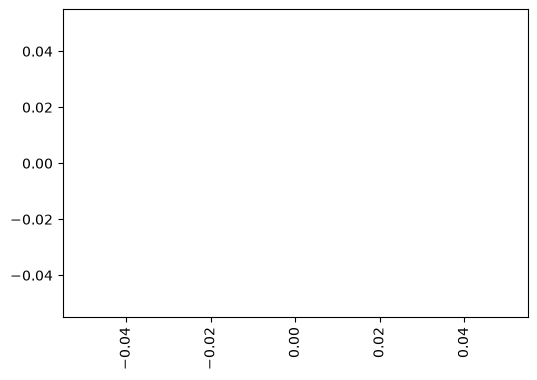

In [242]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(6, 4))

gender_counts.plot(kind="bar")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.show()

#### 8.1.4 Monthly Income Distribution

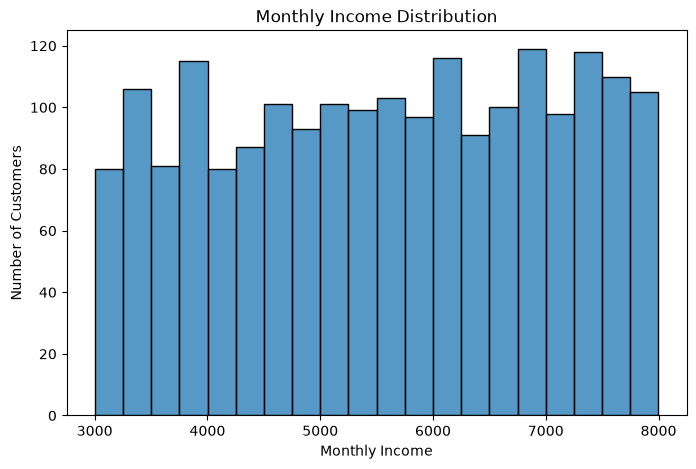

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyIncome", bins=20)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Customers")

plt.show()

#### 8.1.5 Credit Score Distribution

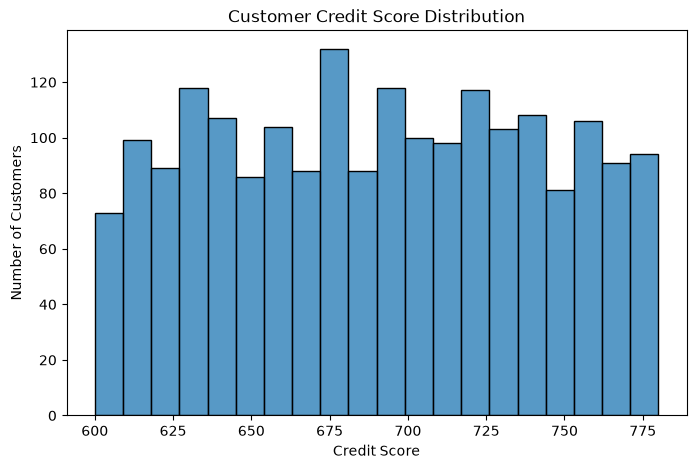

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="CreditScore", bins=20)

plt.title("Customer Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

plt.show()

#### 8.1.6 Customer Distribution by Income Group

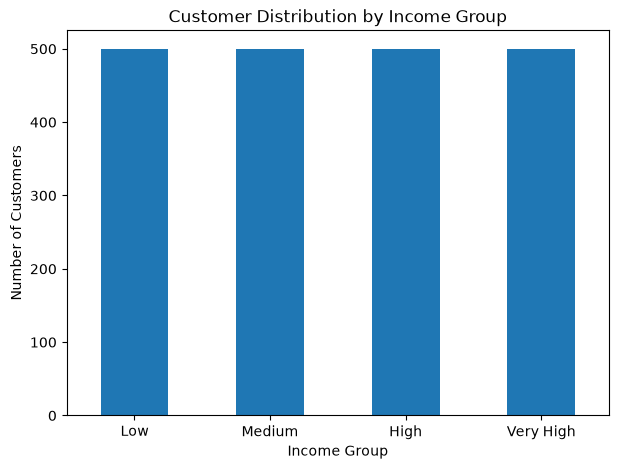

In [ ]:
income_group_counts = df["IncomeGroup"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

income_group_counts.plot(kind="bar")

plt.title("Customer Distribution by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.show()

#### 8.1.7 Customer Distribution by Credit Score Group

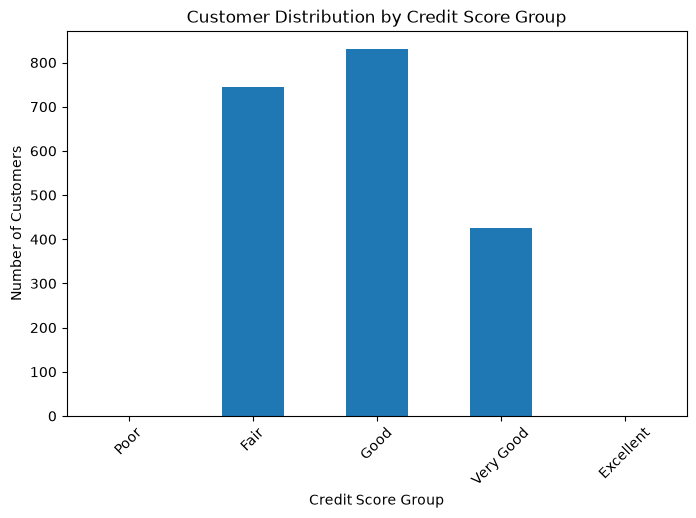

In [ ]:
credit_group_counts = df["CreditScoreGroup"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

credit_group_counts.plot(kind="bar")

plt.title("Customer Distribution by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)

plt.show()

### Customer Analysis Summary

The above visualizations help us understand:

- Customer age distribution
- Age-group composition
- Gender distribution
- Income distribution
- Credit score distribution
- Income-group composition
- Credit-score-group composition

### 8.2 Sales Analysis

Sales analysis is performed to understand revenue, cost, profit, quantity sold, category performance, and product performance.

#### 8.2.1 Overall Sales KPIs

In [ ]:
total_revenue = df["Revenue"].sum()
total_cost = df["TotalCost"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Cost: ₹{total_cost:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")

Total Revenue: ₹1,522,511.00
Total Cost: ₹979,882.00
Total Profit: ₹542,629.00
Total Quantity Sold: 7,055


#### 8.2.2 Revenue and Profit Distribution

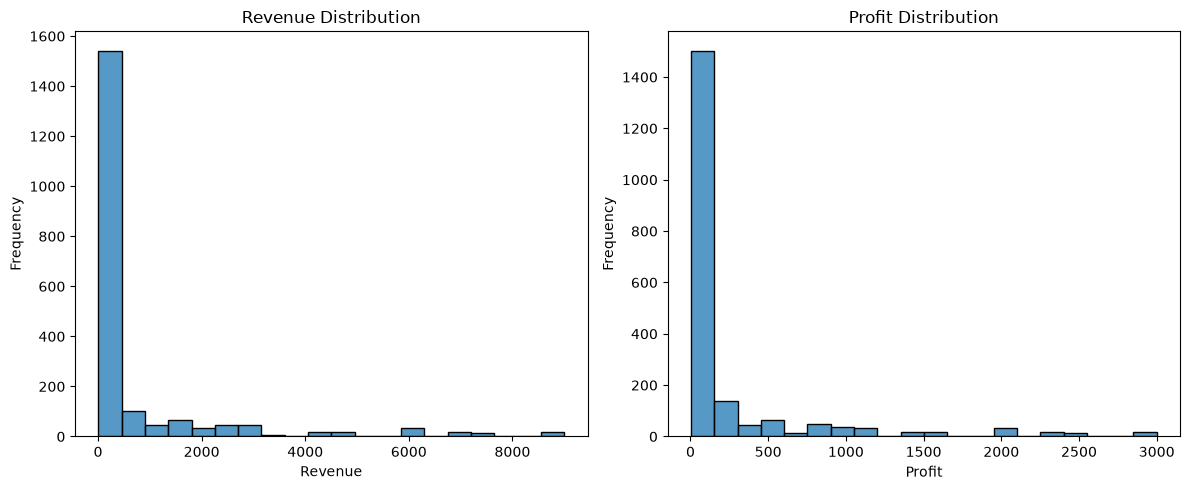

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Revenue"], bins=20, ax=axes[0])
axes[0].set_title("Revenue Distribution")
axes[0].set_xlabel("Revenue")
axes[0].set_ylabel("Frequency")

sns.histplot(df["Profit"], bins=20, ax=axes[1])
axes[1].set_title("Profit Distribution")
axes[1].set_xlabel("Profit")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 8.2.3 Category-wise Sales Performance

In [ ]:
category_performance = (
    df.groupby("Category")
      .agg(
          Revenue=("Revenue", "sum"),
          TotalCost=("TotalCost", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Revenue", ascending=False)
)

category_performance

,Revenue,TotalCost,Profit,Quantity
Category,,,,
electronics,932140,619945,312195,1268
home appliances,416110,256840,159270,1523
fashion,101760,60940,40820,1422
books,38421,22510,15911,1397
toys,34080,19647,14433,1445


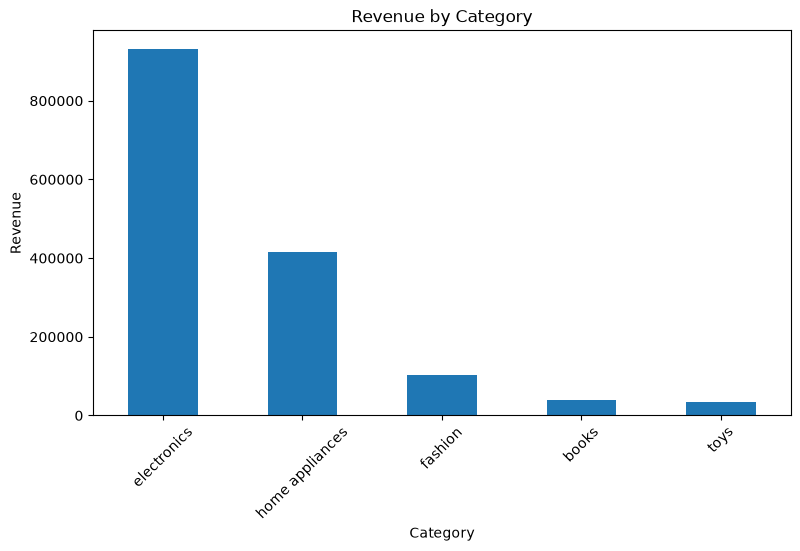

In [ ]:
plt.figure(figsize=(9, 5))

category_performance["Revenue"].plot(kind="bar")

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

#### 8.2.4 Category-wise Profit

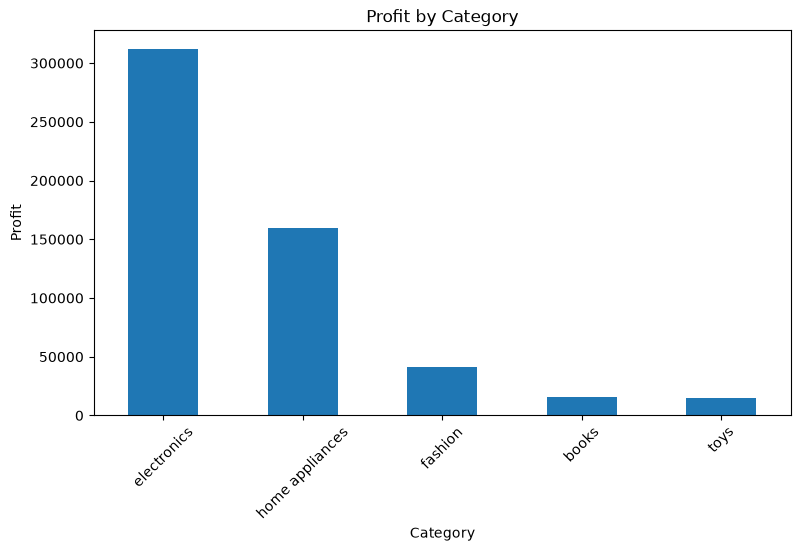

In [ ]:
plt.figure(figsize=(9, 5))

category_performance["Profit"].plot(kind="bar")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.show()

#### 8.2.5 Product-wise Performance

In [ ]:
product_performance = (
    df.groupby("Product")
      .agg(
          Revenue=("Revenue", "sum"),
          TotalCost=("TotalCost", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Revenue", ascending=False)
)

product_performance.head(10)

,Revenue,TotalCost,Profit,Quantity
Product,,,,
television,547500,365000,182500,365
laptop,357600,238400,119200,298
microwave oven,220000,132000,88000,440
electric stove,141600,88500,53100,354
shoes,41600,24960,16640,416
mixer grinder,32310,21540,10770,359
jeans,26740,15280,11460,382
dress,25920,16200,9720,324
toaster,22200,14800,7400,370


#### 8.2.6 Top 10 Products by Revenue

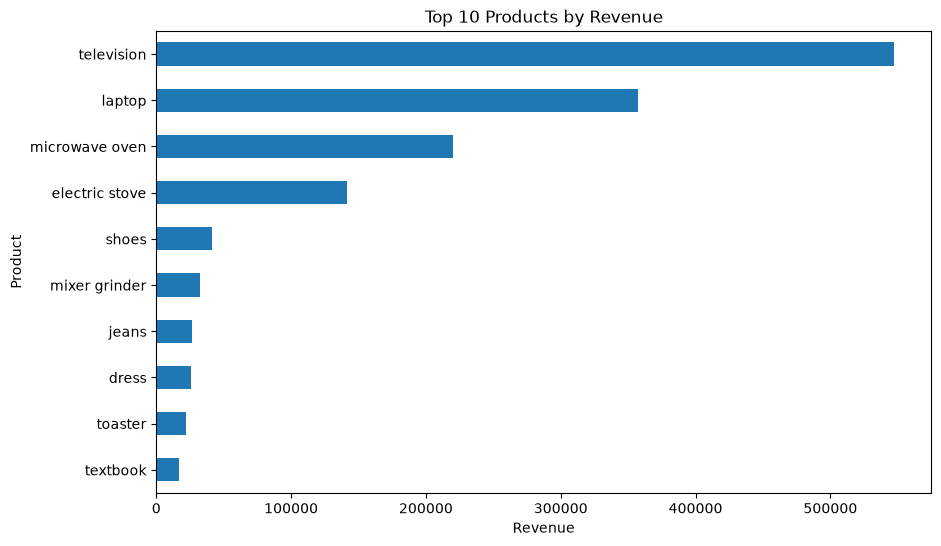

In [ ]:
top_10_products = product_performance.head(10)

plt.figure(figsize=(10, 6))

top_10_products["Revenue"].sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

#### 8.2.7 Top 10 Products by Profit

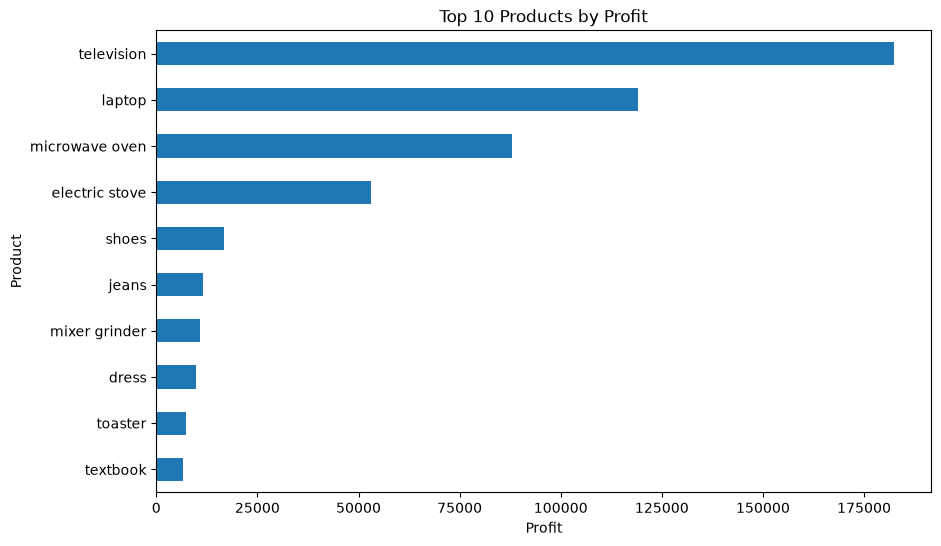

In [ ]:
top_10_profit_products = (
    product_performance
    .sort_values("Profit", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

top_10_profit_products["Profit"].sort_values().plot(kind="barh")

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit")
plt.ylabel("Product")

plt.show()

#### 8.2.8 Revenue vs Profit by Product

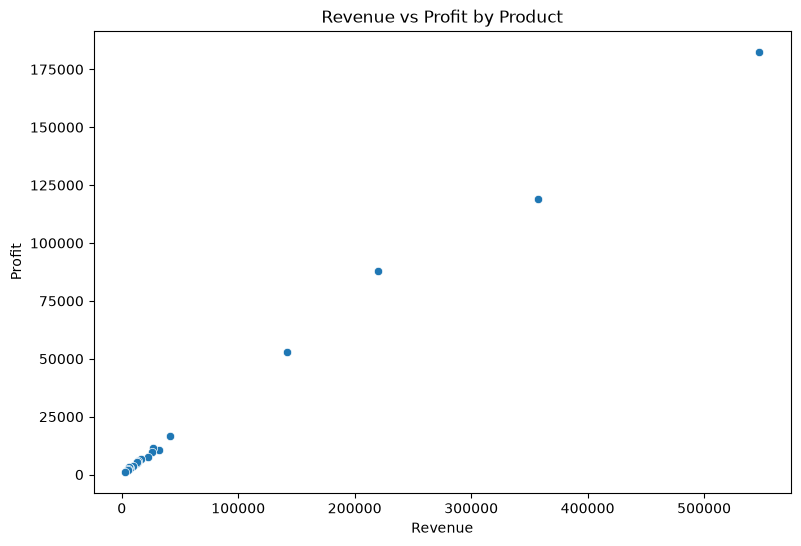

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=product_performance,
    x="Revenue",
    y="Profit"
)

plt.title("Revenue vs Profit by Product")
plt.xlabel("Revenue")
plt.ylabel("Profit")

plt.show()

### Sales Analysis Summary

The analysis helps identify:

- Overall revenue and profit
- Best-performing categories
- Best-performing products
- Products generating the highest revenue
- Products generating the highest profit
- Relationship between revenue and profit

### 8.3 Geographic Analysis

Geographic analysis helps us understand how revenue, profit, and sales vary across different countries, states, and cities.

#### 8.3.1 Country-wise Performance

In [ ]:
country_performance = (
    df.groupby("Country")
      .agg(
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

country_performance

,Revenue,Profit,Quantity,Customers
Country,,,,
Canada,192416,68607,887,147
China,188607,67607,825,138
Spain,179445,63685,780,134
Italy,174219,61801,751,126
Australia,171763,61490,861,150
India,171417,61237,905,151
USA,162879,57832,687,115
Japan,162527,57262,706,123
UK,119238,43108,653,116


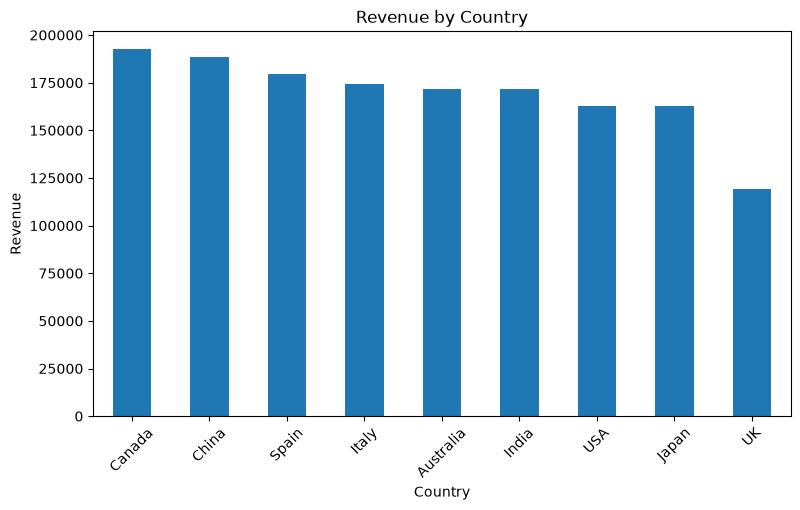

In [ ]:
plt.figure(figsize=(9, 5))

country_performance["Revenue"].plot(kind="bar")

plt.title("Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

#### 8.3.2 State-wise Performance

In [ ]:
state_performance = (
    df.groupby("State")
      .agg(
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

state_performance.head(10)

,Revenue,Profit,Quantity,Customers
State,,,,
Maharashtra,116410,40961,541,86
Quebec,110877,38812,418,70
New South Wales,108021,38735,495,82
Lombardy,103321,37032,438,68
Shandong,96727,34660,422,67
Catalonia,94012,33103,398,68
Guangdong,91880,32947,403,71
California,88102,30969,363,59
Kanagawa,87150,30823,350,60


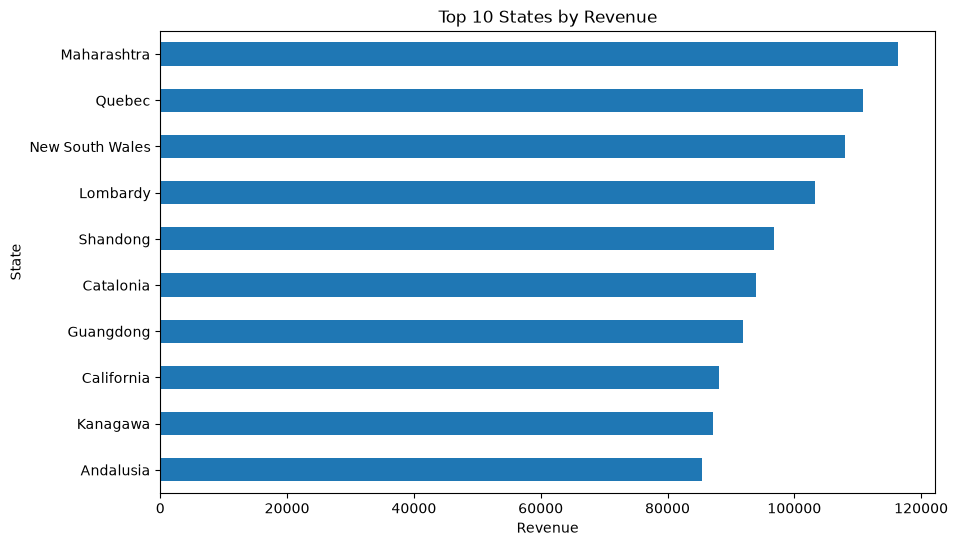

In [ ]:
top_10_states = state_performance.head(10)

plt.figure(figsize=(10, 6))

top_10_states["Revenue"].sort_values().plot(kind="barh")

plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue")
plt.ylabel("State")

plt.show()

#### 8.3.3 City-wise Performance

In [ ]:
city_performance = (
    df.groupby("City")
      .agg(
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

city_performance.head(10)

,Revenue,Profit,Quantity,Customers
City,,,,
Qingdao,57609,20046,171,27
Tokyo,54012,18710,167,28
Mumbai,52963,18444,186,27
Barcelona,49088,17182,156,22
Wollongong,47906,16810,167,23
Yokohama,46977,16388,206,38
Brescia,44477,15774,175,25
Quebec City,43571,14805,115,19
Montreal,40145,14107,160,27


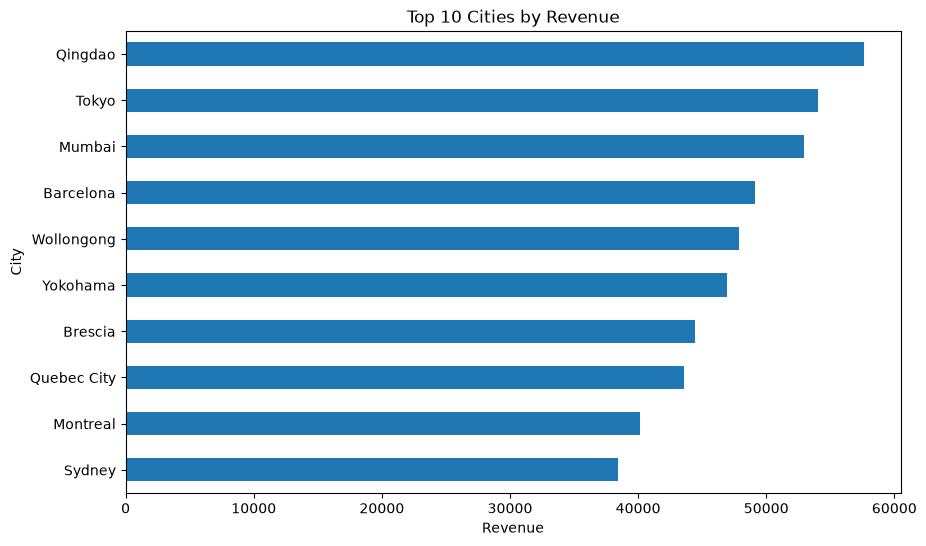

In [ ]:
top_10_cities = city_performance.head(10)

plt.figure(figsize=(10, 6))

top_10_cities["Revenue"].sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Revenue")
plt.xlabel("Revenue")
plt.ylabel("City")

plt.show()

#### 8.3.4 Revenue vs Profit by Country

In [ ]:
country_performance = (
    df.groupby("Country")
      .agg(
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

country_performance

,Revenue,Profit,Quantity,Customers
Country,,,,
Canada,192416,68607,887,147
China,188607,67607,825,138
Spain,179445,63685,780,134
Italy,174219,61801,751,126
Australia,171763,61490,861,150
India,171417,61237,905,151
USA,162879,57832,687,115
Japan,162527,57262,706,123
UK,119238,43108,653,116


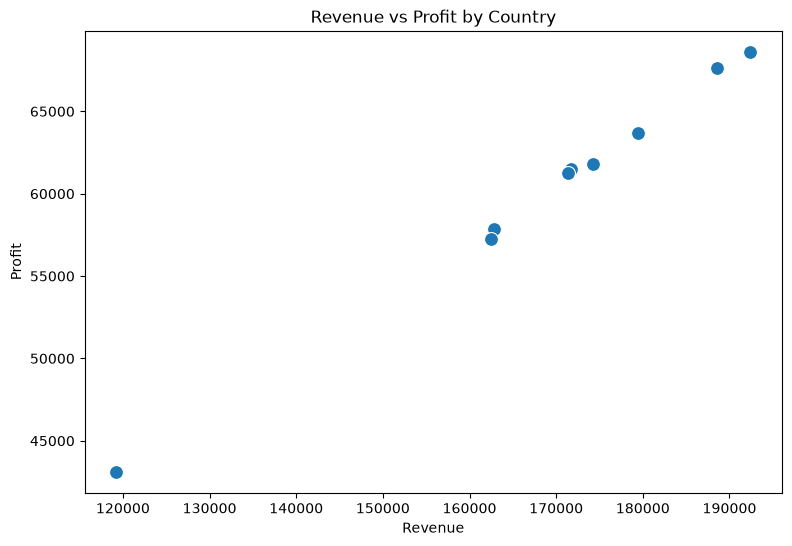

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=country_performance,
    x="Revenue",
    y="Profit",
    s=100
)

plt.title("Revenue vs Profit by Country")
plt.xlabel("Revenue")
plt.ylabel("Profit")

plt.show()

### Geographic Analysis Summary

The analysis helps identify:

- Revenue contribution by country
- Profit contribution by country
- Top-performing states
- Top-performing cities
- Geographic areas with high revenue but relatively low profit

## 8.4 Customer Journey Analysis

### 8.4.1 Session Duration Analysis

In [243]:
session_duration_stats = df["SessionDurationMinutes"].describe()

session_duration_stats

count    2000.000000
mean       21.076000
std         8.247013
min         3.000000
25%        14.000000
50%        21.000000
75%        28.000000
max        40.000000
Name: SessionDurationMinutes, dtype: float64

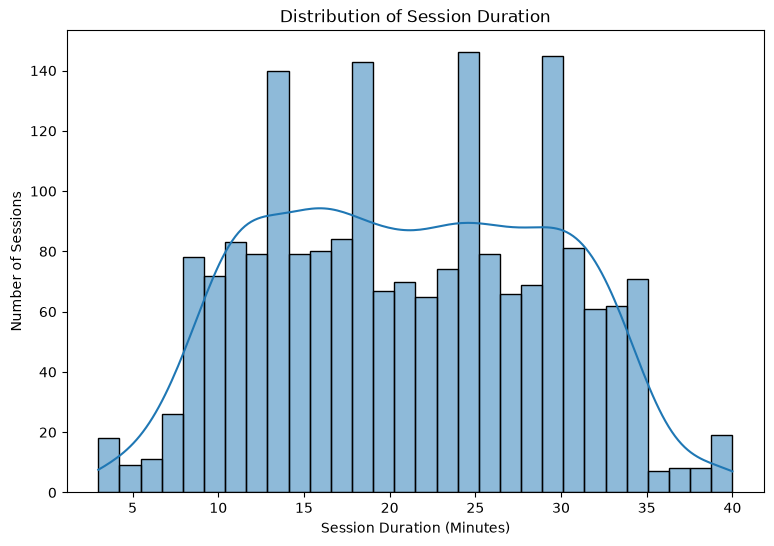

In [244]:
plt.figure(figsize=(9, 6))

sns.histplot(
    df["SessionDurationMinutes"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Session Duration")
plt.xlabel("Session Duration (Minutes)")
plt.ylabel("Number of Sessions")

plt.show()

### 8.4.2 Order Conversion Analysis

In [245]:
total_sessions = len(df)

total_orders = df["OrderFlag"].sum()

conversion_rate = (total_orders / total_sessions) * 100

print("Total Sessions:", total_sessions)
print("Confirmed Orders:", total_orders)
print("Conversion Rate:", round(conversion_rate, 2), "%")

Total Sessions: 2000
Confirmed Orders: 1700
Conversion Rate: 85.0 %


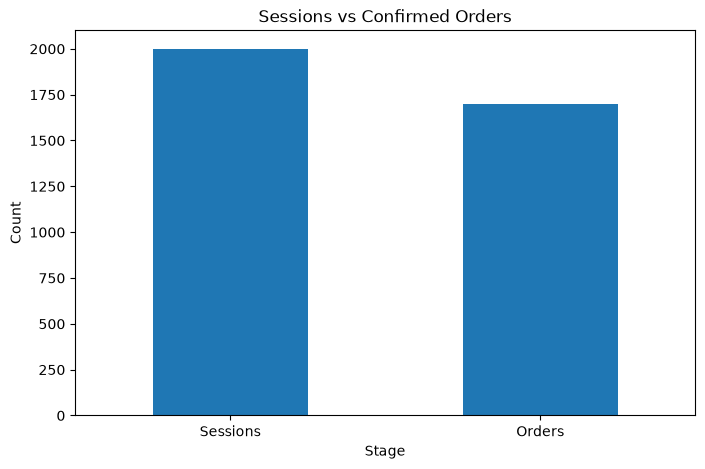

In [246]:
conversion_data = pd.Series({
    "Sessions": total_sessions,
    "Orders": total_orders
})

plt.figure(figsize=(8, 5))

conversion_data.plot(kind="bar")

plt.title("Sessions vs Confirmed Orders")
plt.xlabel("Stage")
plt.ylabel("Count")

plt.xticks(rotation=0)

plt.show()

### 8.4.3 Cart-to-Order Time Analysis

In [247]:
cart_to_order = df.loc[
    df["OrderFlag"] == 1,
    "CartToOrderMinutes"
].dropna()

cart_to_order.describe()

count    1700.000000
mean        9.898824
std         3.183481
min         5.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        15.000000
Name: CartToOrderMinutes, dtype: float64

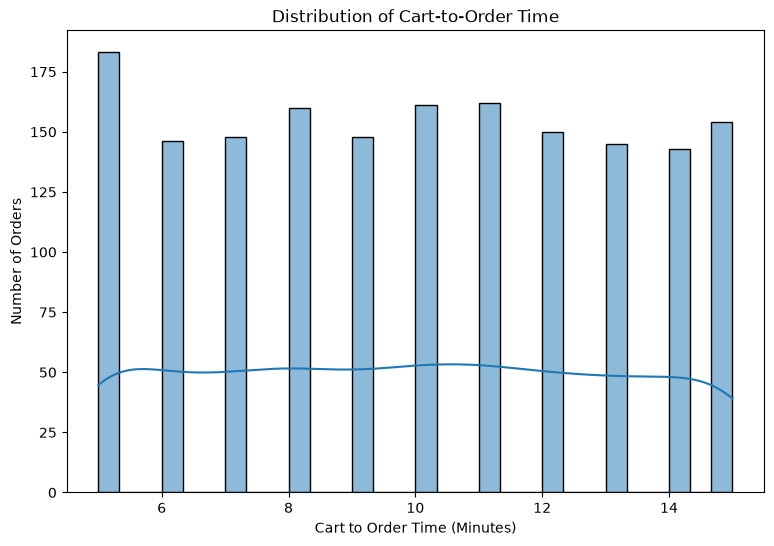

In [248]:
plt.figure(figsize=(9, 6))

sns.histplot(
    cart_to_order,
    bins=30,
    kde=True
)

plt.title("Distribution of Cart-to-Order Time")
plt.xlabel("Cart to Order Time (Minutes)")
plt.ylabel("Number of Orders")

plt.show()

### 8.4.4 Customer Journey Funnel

In [249]:
journey_data = pd.Series({
    "Sessions": len(df),
    "Cart Added": df["CartAdditionTime"].notna().sum(),
    "Orders": df["OrderFlag"].sum(),
    "Returned Orders": df["ReturnFlag"].sum()
})

journey_data

Sessions           2000.0
Cart Added         2000.0
Orders             1700.0
Returned Orders     236.0
dtype: float64

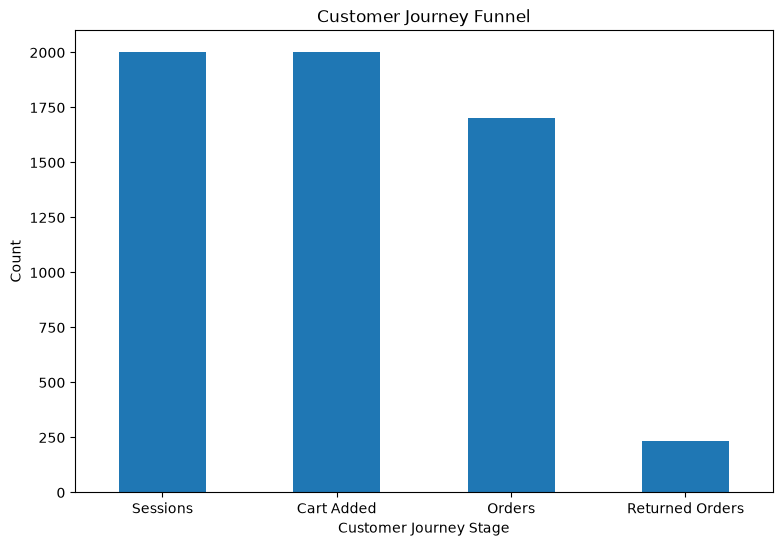

In [250]:
plt.figure(figsize=(9, 6))

journey_data.plot(kind="bar")

plt.title("Customer Journey Funnel")
plt.xlabel("Customer Journey Stage")
plt.ylabel("Count")

plt.xticks(rotation=0)

plt.show()

### Customer Journey Analysis Summary

The customer journey analysis evaluates session duration, order conversion, cart-to-order time, and returned orders. These metrics help identify customer engagement, conversion performance, and potential friction in the purchasing process.

## 8.5 Campaign Analysis

### 8.5.1 Campaign-wise Performance

In [251]:
campaign_performance = (
    df.groupby("CampaignSchema ")
      .agg(
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Orders=("OrderFlag", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

campaign_performance

,Revenue,Profit,Quantity,Orders,Customers
CampaignSchema,,,,,
Instagram-ads,328177,115376,1258,300,330
Google-ads,267390,96126,1214,296,319
Billboard-QR code,258967,91913,1069,278,294
Facebook-ads,229802,82194,1192,288,305
Twitter-ads,227393,80949,1131,265,278
E-mails,210782,76071,1191,273,313


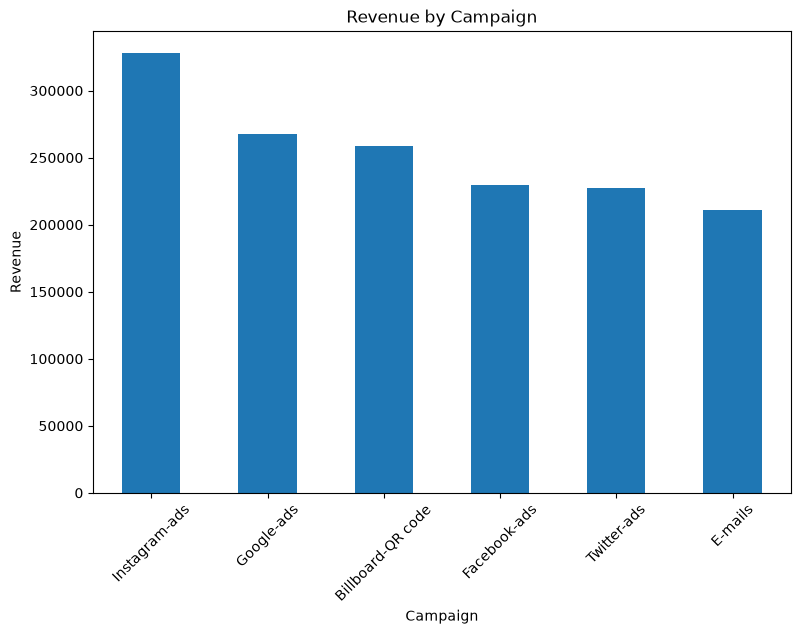

In [252]:
plt.figure(figsize=(9, 6))

campaign_performance["Revenue"].plot(kind="bar")

plt.title("Revenue by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

### 8.5.2 Profit by Campaign

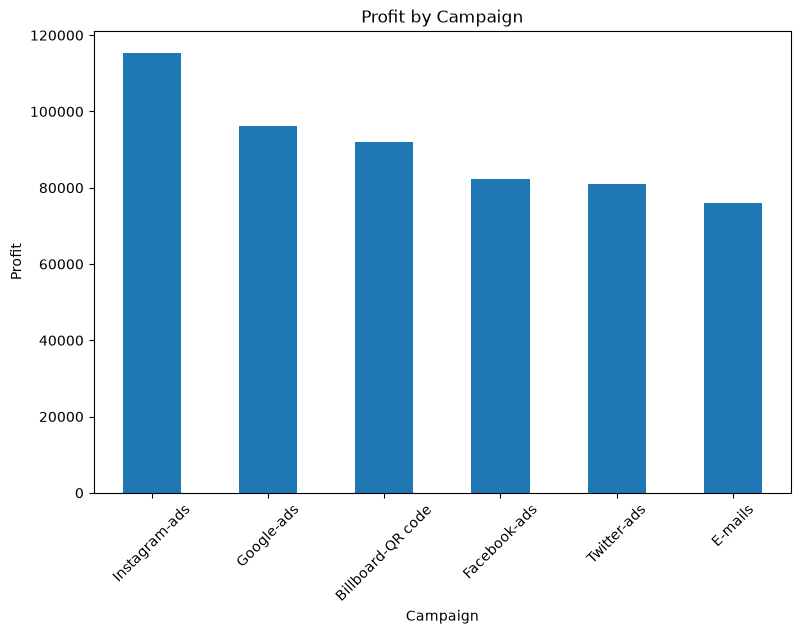

In [253]:
plt.figure(figsize=(9, 6))

campaign_performance["Profit"].plot(kind="bar")

plt.title("Profit by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.show()

### 8.5.3 Orders by Campaign

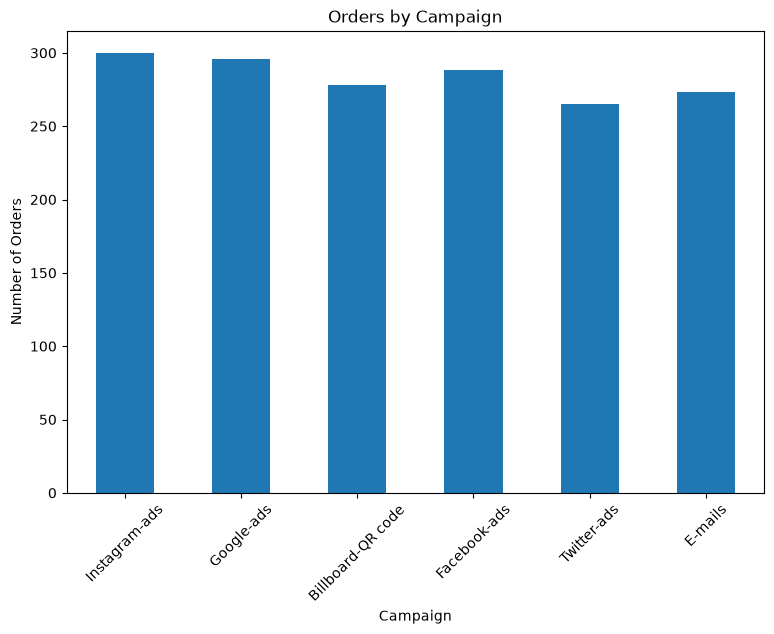

In [254]:
plt.figure(figsize=(9, 6))

campaign_performance["Orders"].plot(kind="bar")

plt.title("Orders by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

### 8.5.4 Campaign Conversion Rate

In [255]:
campaign_sessions = (
    df.groupby("CampaignSchema ")
      .size()
      .rename("Sessions")
)

campaign_conversion = campaign_performance[["Orders"]].join(
    campaign_sessions
)

campaign_conversion["ConversionRate"] = (
    campaign_conversion["Orders"] /
    campaign_conversion["Sessions"]
) * 100

campaign_conversion.sort_values(
    "ConversionRate",
    ascending=False
)

,Orders,Sessions,ConversionRate
CampaignSchema,,,
Billboard-QR code,278,317,87.697161
Twitter-ads,265,308,86.038961
Google-ads,296,345,85.797101
Facebook-ads,288,338,85.207101
Instagram-ads,300,361,83.102493
E-mails,273,331,82.477341


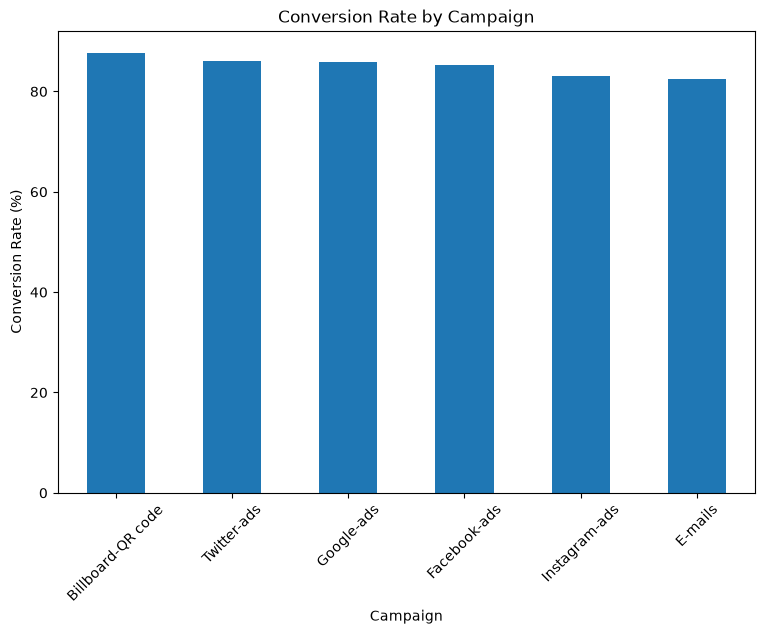

In [256]:
plt.figure(figsize=(9, 6))

campaign_conversion["ConversionRate"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Conversion Rate by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Conversion Rate (%)")

plt.xticks(rotation=45)

plt.show()

### Campaign Analysis Summary

Campaign performance is evaluated using revenue, profit, orders, customers, and conversion rate. This analysis helps identify differences in campaign performance and customer conversion behavior.

## 8.6 Return & Customer Retention Analysis

### 8.6.1 Overall Return Analysis

In [257]:
total_orders = df["OrderFlag"].sum()

total_returns = df["ReturnFlag"].sum()

return_rate = (total_returns / total_orders) * 100

print("Total Orders:", total_orders)
print("Total Returned Orders:", int(total_returns))
print("Return Rate:", round(return_rate, 2), "%")

Total Orders: 1700
Total Returned Orders: 236
Return Rate: 13.88 %


### 8.6.2 Return Reason Analysis

In [258]:
return_reasons = (
    df.loc[df["ReturnFlag"] == 1, "ReturnReason"]
      .value_counts()
)

return_reasons

ReturnReason
Poor Value         55
Wrong Item         49
Arrived Late       47
Arrived Damaged    45
Poor Quality       40
Name: count, dtype: int64

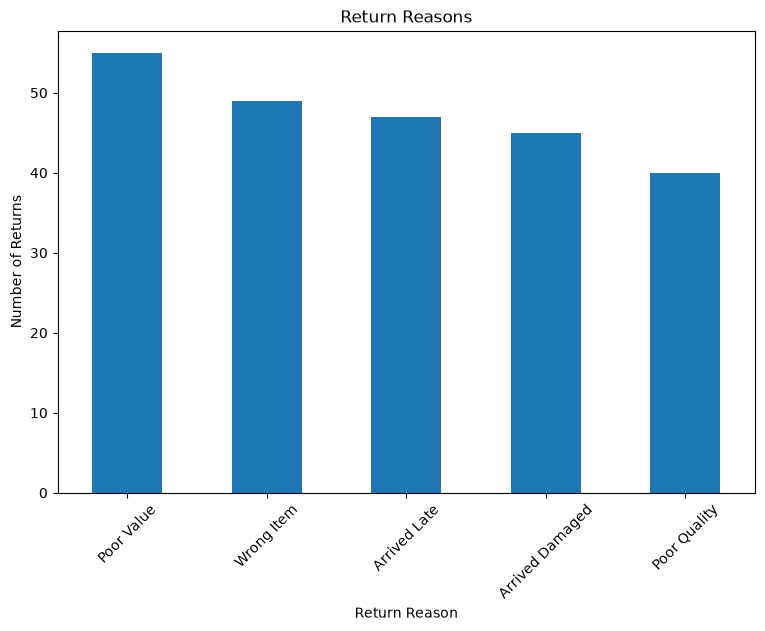

In [259]:
plt.figure(figsize=(9, 6))

return_reasons.plot(kind="bar")

plt.title("Return Reasons")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")

plt.xticks(rotation=45)

plt.show()

### 8.6.3 Returns by Category

In [260]:
category_returns = (
    df[df["ReturnFlag"] == 1]
      .groupby("Category")
      .agg(
          Returns=("ReturnFlag", "sum"),
          Revenue=("Revenue", "sum")
      )
      .sort_values("Returns", ascending=False)
)

category_returns

,Returns,Revenue
Category,,
fashion,51.0,13545
books,50.0,4149
toys,50.0,4575
home appliances,49.0,48310
electronics,36.0,79600


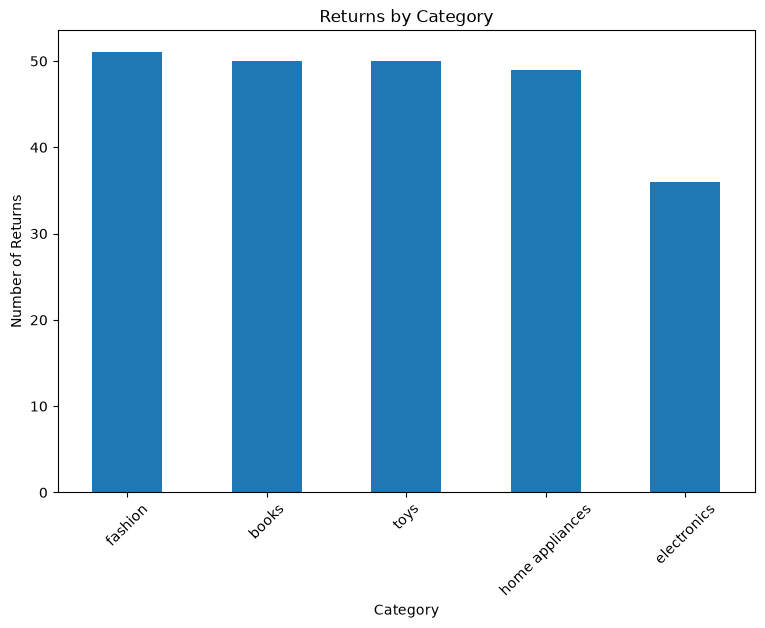

In [261]:
plt.figure(figsize=(9, 6))

category_returns["Returns"].plot(kind="bar")

plt.title("Returns by Category")
plt.xlabel("Category")
plt.ylabel("Number of Returns")

plt.xticks(rotation=45)

plt.show()

### 8.6.4 Returns by Product

In [262]:
product_returns = (
    df[df["ReturnFlag"] == 1]
      .groupby("Product")
      .agg(
          Returns=("ReturnFlag", "sum"),
          Revenue=("Revenue", "sum")
      )
      .sort_values("Returns", ascending=False)
)

product_returns.head(10)

,Returns,Revenue
Product,,
mixer grinder,19.0,6930
shoes,18.0,7300
magazine,17.0,480
action figure,15.0,945
plush toy,14.0,1080
novel,13.0,684
board game,13.0,1750
dress,13.0,3280
microwave oven,12.0,24000


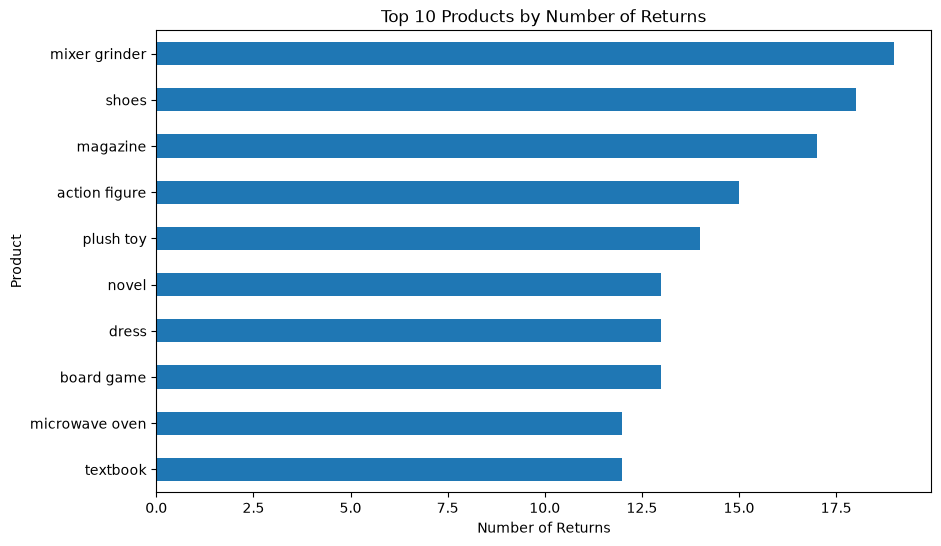

In [263]:
plt.figure(figsize=(10, 6))

product_returns.head(10)["Returns"].sort_values().plot(kind="barh")

plt.title("Top 10 Products by Number of Returns")
plt.xlabel("Number of Returns")
plt.ylabel("Product")

plt.show()

### 8.6.5 Returns by Campaign

In [264]:
campaign_returns = (
    df[df["ReturnFlag"] == 1]
      .groupby("CampaignSchema ")
      .agg(
          Returns=("ReturnFlag", "sum"),
          Revenue=("Revenue", "sum")
      )
      .sort_values("Returns", ascending=False)
)

campaign_returns

,Returns,Revenue
CampaignSchema,,
Google-ads,48.0,32989
Billboard-QR code,42.0,23862
Facebook-ads,41.0,25854
E-mails,37.0,13506
Instagram-ads,35.0,33071
Twitter-ads,33.0,20897


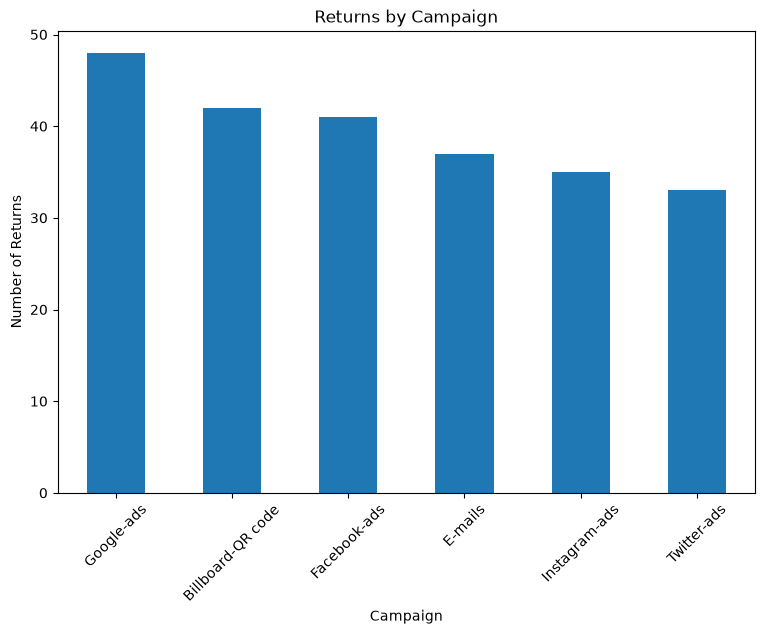

In [265]:
plt.figure(figsize=(9, 6))

campaign_returns["Returns"].plot(kind="bar")

plt.title("Returns by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Number of Returns")

plt.xticks(rotation=45)

plt.show()

### Return Analysis Summary

Return analysis measures the overall return rate and examines return reasons across categories, products, and campaigns. These metrics help identify products or business segments associated with higher return activity.

## 8.7 Payment Method Analysis

### 8.7.1 Payment Method Performance

In [266]:
payment_performance = (
    df[df["OrderFlag"] == 1]
      .groupby("PaymentMethod")
      .agg(
          Orders=("OrderFlag", "sum"),
          Revenue=("Revenue", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

payment_performance

,Orders,Revenue,Profit,Quantity,Customers
PaymentMethod,,,,,
Credit Card,583,458482,163855,2100,497
Debit Card,528,374234,133646,1886,471
Cash On Delivery,408,320237,113212,1434,361
Paypal,181,130670,47199,614,170


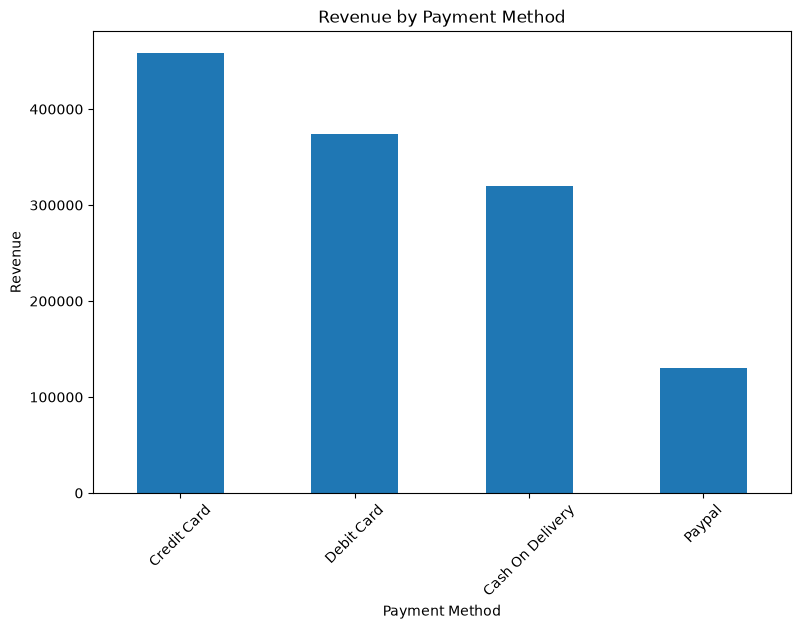

In [267]:
plt.figure(figsize=(9, 6))

payment_performance["Revenue"].plot(kind="bar")

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

### 8.7.2 Orders by Payment Method

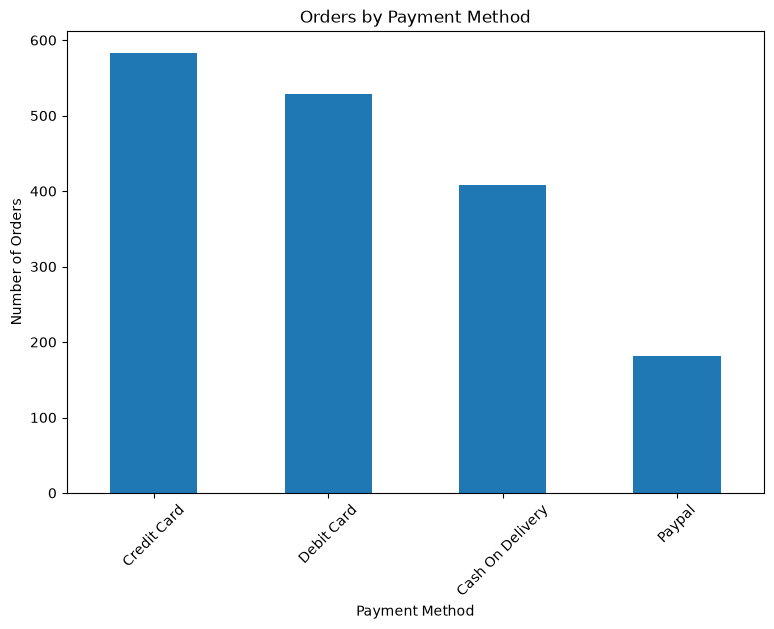

In [268]:
plt.figure(figsize=(9, 6))

payment_performance["Orders"].plot(kind="bar")

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

### 8.7.3 Profit by Payment Method

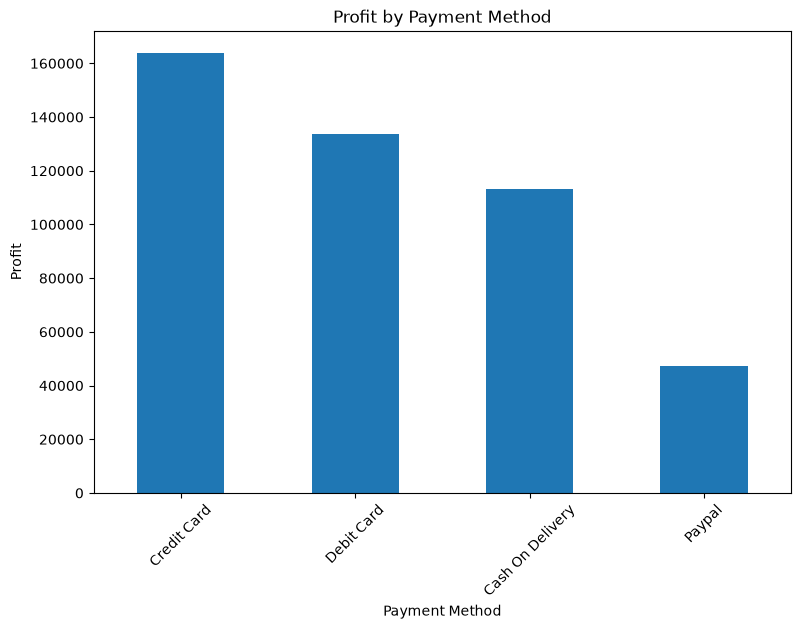

In [269]:
plt.figure(figsize=(9, 6))

payment_performance["Profit"].plot(kind="bar")

plt.title("Profit by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.show()

### 8.7.4 Payment Method Summary

In [270]:
payment_summary = payment_performance.copy()

payment_summary["AverageOrderValue"] = (
    payment_summary["Revenue"] /
    payment_summary["Orders"]
)

payment_summary["ProfitMargin"] = (
    payment_summary["Profit"] /
    payment_summary["Revenue"]
) * 100

payment_summary.round(2)

,Orders,Revenue,Profit,Quantity,Customers,AverageOrderValue,ProfitMargin
PaymentMethod,,,,,,,
Credit Card,583,458482,163855,2100,497,786.42,35.74
Debit Card,528,374234,133646,1886,471,708.78,35.71
Cash On Delivery,408,320237,113212,1434,361,784.89,35.35
Paypal,181,130670,47199,614,170,721.93,36.12


### Payment Method Analysis Summary

Payment method analysis compares order volume, revenue, profit, customers, average order value, and profit margin across different payment methods. This helps understand customer payment preferences and their relationship with business performance.

## 8.8 Time-Based Analysis

### 8.8.1 Extract Date and Time Features

In [271]:
df["SessionDate"] = df["SessionStart"].dt.date
df["SessionHour"] = df["SessionStart"].dt.hour
df["SessionDay"] = df["SessionStart"].dt.day_name()
df["SessionMonth"] = df["SessionStart"].dt.month_name()

df[[
    "SessionStart",
    "SessionDate",
    "SessionHour",
    "SessionDay",
    "SessionMonth"
]].head()

,SessionStart,SessionDate,SessionHour,SessionDay,SessionMonth
0,2019-01-01 02:42:00,2019-01-01,2,Tuesday,January
1,2019-01-02 20:35:00,2019-01-02,20,Wednesday,January
2,2019-01-04 03:11:00,2019-01-04,3,Friday,January
3,2019-01-05 09:01:00,2019-01-05,9,Saturday,January
4,2019-01-05 13:35:00,2019-01-05,13,Saturday,January


### 8.8.2 Revenue by Hour

In [272]:
hourly_revenue = (
    df.groupby("SessionHour")
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("OrderFlag", "sum")
      )
      .sort_index()
)

hourly_revenue

,Revenue,Orders
SessionHour,,
0,60104,71
1,74467,92
2,69994,78
3,67597,65
4,51259,67
5,56361,65
6,65865,62
7,73712,62
8,48814,63


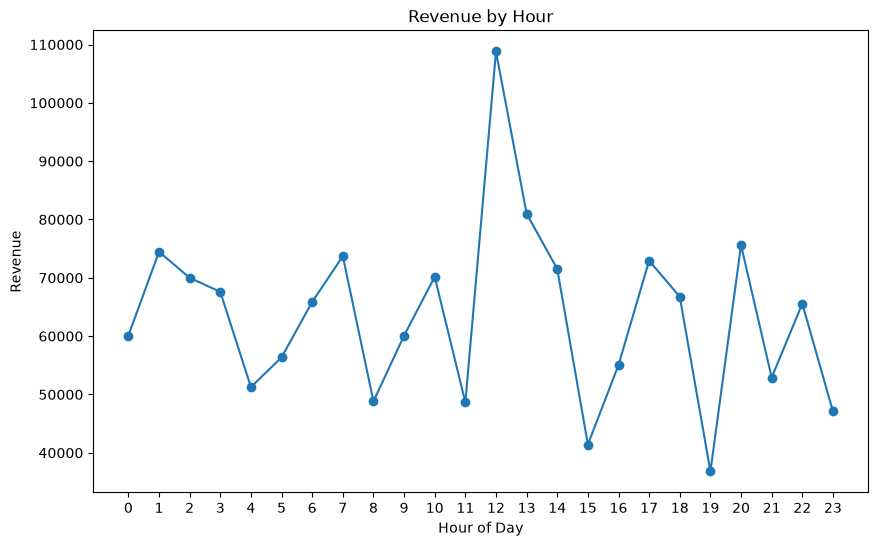

In [273]:
plt.figure(figsize=(10, 6))

hourly_revenue["Revenue"].plot(kind="line", marker="o")

plt.title("Revenue by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(24))

plt.show()

### 8.8.3 Orders by Hour

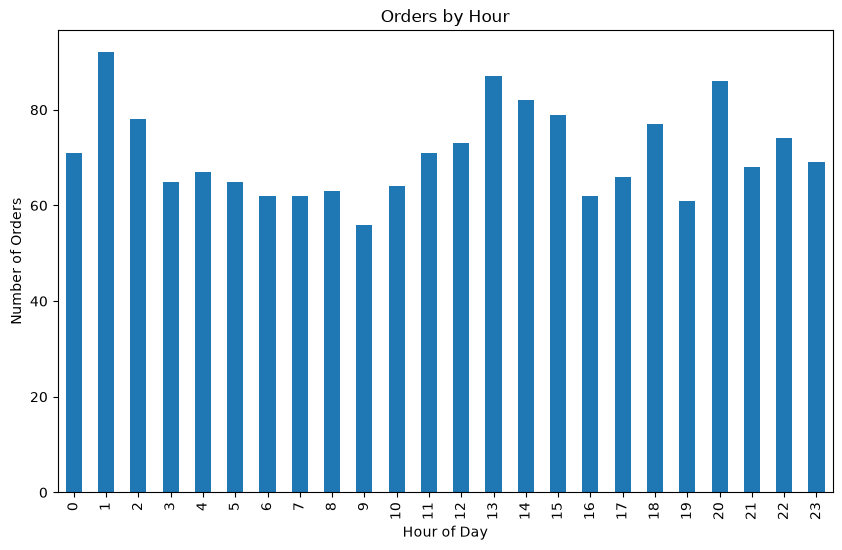

In [274]:
plt.figure(figsize=(10, 6))

hourly_revenue["Orders"].plot(kind="bar")

plt.title("Orders by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")

plt.show()

### 8.8.4 Revenue by Day of Week

In [275]:
daily_revenue = (
    df.groupby("SessionDay")
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("OrderFlag", "sum")
      )
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_revenue = daily_revenue.reindex(day_order)

daily_revenue

,Revenue,Orders
SessionDay,,
Monday,161325,200
Tuesday,221914,271
Wednesday,236306,253
Thursday,197636,258
Friday,244803,268
Saturday,224949,226
Sunday,235578,224


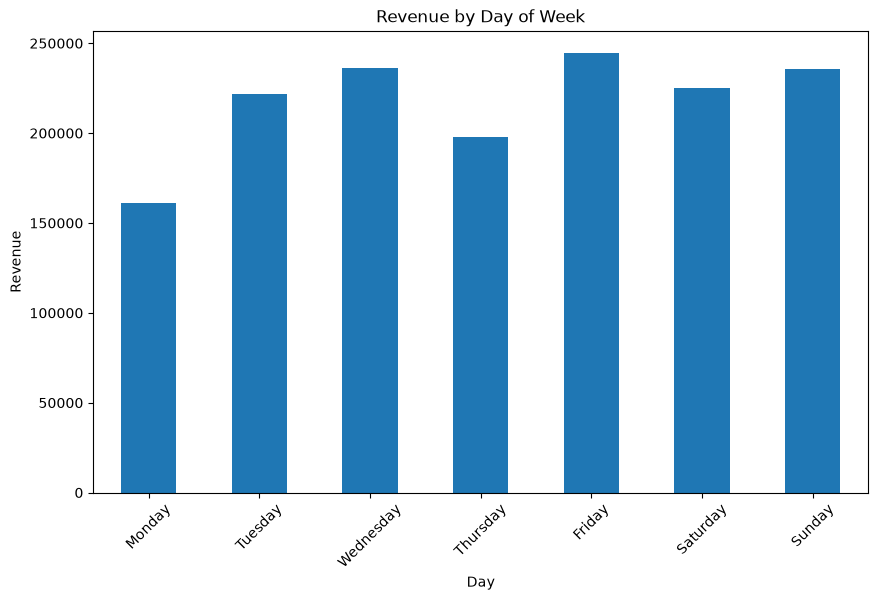

In [276]:
plt.figure(figsize=(10, 6))

daily_revenue["Revenue"].plot(kind="bar")

plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

### 8.8.5 Monthly Revenue Analysis

In [277]:
monthly_revenue = (
    df.groupby("SessionMonth")
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("OrderFlag", "sum")
      )
)

monthly_revenue

,Revenue,Orders
SessionMonth,,
April,145547,138
August,117574,157
December,133920,158
February,131749,132
January,102744,136
July,117266,154
June,106754,147
March,132776,131
May,149560,144


In [278]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_revenue = monthly_revenue.reindex(month_order)

monthly_revenue

,Revenue,Orders
SessionMonth,,
January,102744,136
February,131749,132
March,132776,131
April,145547,138
May,149560,144
June,106754,147
July,117266,154
August,117574,157
September,139483,139


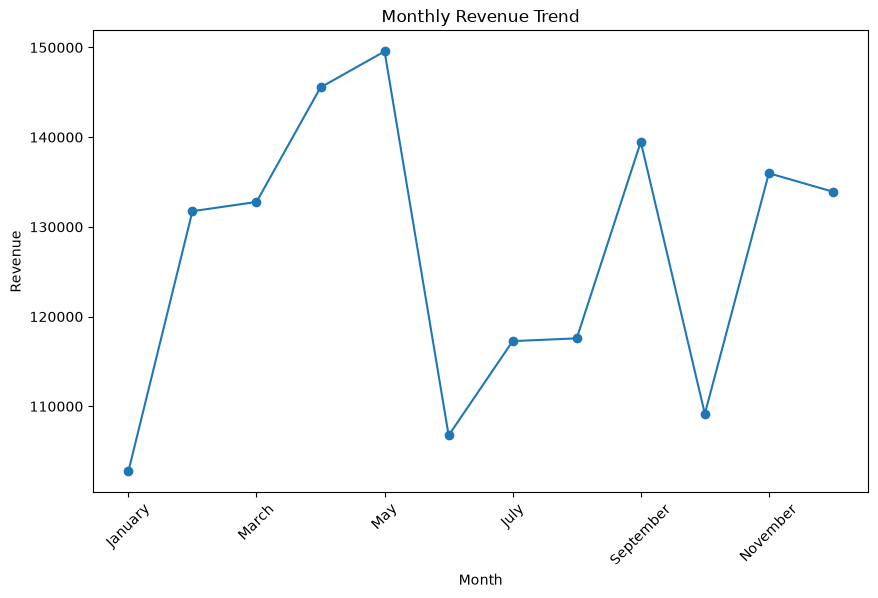

In [279]:
plt.figure(figsize=(10, 6))

monthly_revenue["Revenue"].plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

### Time-Based Analysis Summary

Time-based analysis examines customer sessions, orders, and revenue across different hours, days of the week, and months. These patterns can help identify periods of higher customer activity and sales.

## 8.9 Customer Segmentation Analysis

### 8.9.1 Customer-Level Summary

In [280]:
customer_summary = (
    df.groupby("CustomerID")
      .agg(
          Age=("Age", "first"),
          Gender=("Gender", "first"),
          MonthlyIncome=("MonthlyIncome", "first"),
          CreditScore=("CreditScore", "first"),
          TotalOrders=("OrderFlag", "sum"),
          TotalRevenue=("Revenue", "sum"),
          TotalProfit=("Profit", "sum"),
          TotalQuantity=("Quantity", "sum"),
          TotalReturns=("ReturnFlag", "sum")
      )
)

customer_summary.head()

,Age,Gender,MonthlyIncome,CreditScore,TotalOrders,TotalRevenue,TotalProfit,TotalQuantity,TotalReturns
CustomerID,,,,,,,,,
1001,57,NaT,7591,780,2,272,112,8,0.0
1002,69,NaT,3912,746,2,1080,420,12,0.0
1003,21,NaT,7460,772,1,40,16,2,0.0
1004,67,NaT,4765,631,2,2040,816,6,0.0
1005,57,NaT,3268,630,1,600,240,6,0.0


In [281]:
customer_summary["CustomerSegment"] = pd.qcut(
    customer_summary["TotalRevenue"],
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ],
    duplicates="drop"
)

customer_summary.head()

,Age,Gender,MonthlyIncome,CreditScore,TotalOrders,TotalRevenue,TotalProfit,TotalQuantity,TotalReturns,CustomerSegment
CustomerID,,,,,,,,,,
1001,57,NaT,7591,780,2,272,112,8,0.0,Medium Value
1002,69,NaT,3912,746,2,1080,420,12,0.0,High Value
1003,21,NaT,7460,772,1,40,16,2,0.0,Low Value
1004,67,NaT,4765,631,2,2040,816,6,0.0,Very High Value
1005,57,NaT,3268,630,1,600,240,6,0.0,High Value


### 8.9.2 Customer Segment Distribution

In [282]:
segment_counts = customer_summary["CustomerSegment"].value_counts().sort_index()

segment_counts

CustomerSegment
Low Value          300
Medium Value       300
High Value         304
Very High Value    296
Name: count, dtype: int64

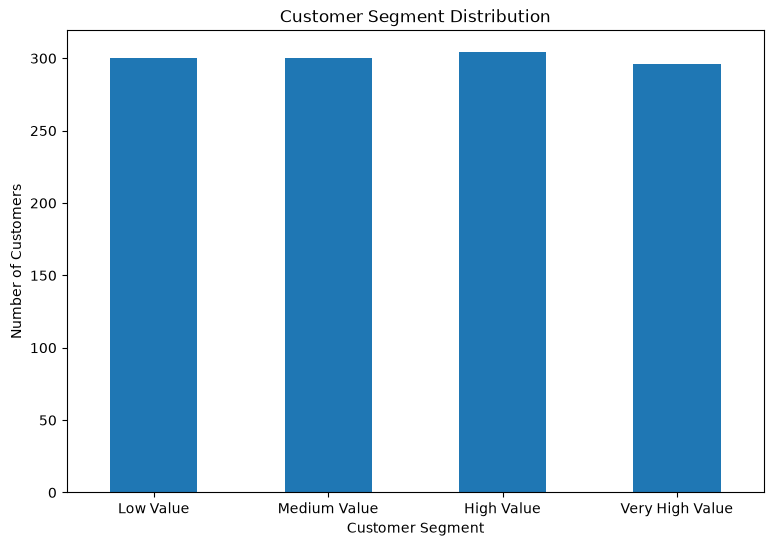

In [283]:
plt.figure(figsize=(9, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.show()

### 8.9.3 Revenue by Customer Segment

In [284]:
segment_performance = (
    customer_summary.groupby("CustomerSegment", observed=True)
    .agg(
        Customers=("TotalRevenue", "count"),
        Revenue=("TotalRevenue", "sum"),
        Profit=("TotalProfit", "sum"),
        Orders=("TotalOrders", "sum"),
        Quantity=("TotalQuantity", "sum")
    )
)

segment_performance

,Customers,Revenue,Profit,Orders,Quantity
CustomerSegment,,,,,
Low Value,300,19941,8179,289,883
Medium Value,300,63881,25267,397,1622
High Value,304,191151,72548,499,2208
Very High Value,296,1247538,436635,515,2342


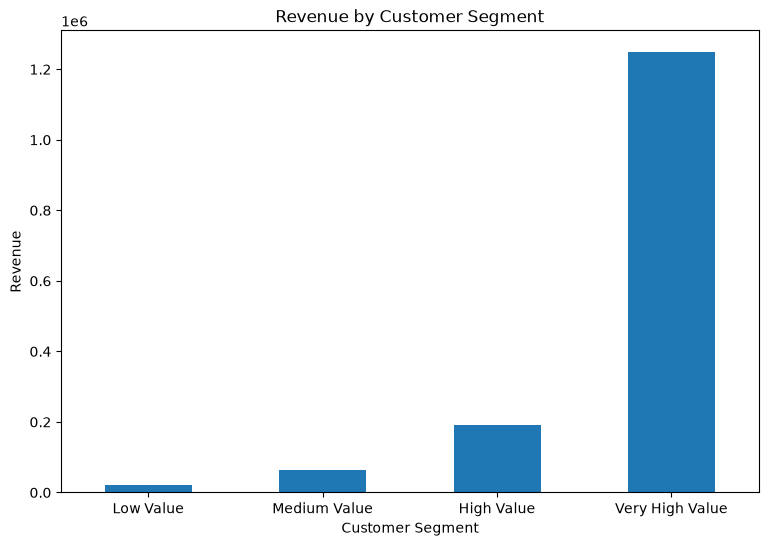

In [285]:
plt.figure(figsize=(9, 6))

segment_performance["Revenue"].plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")

plt.xticks(rotation=0)

plt.show()

### 8.9.4 Customer Segment vs Profit

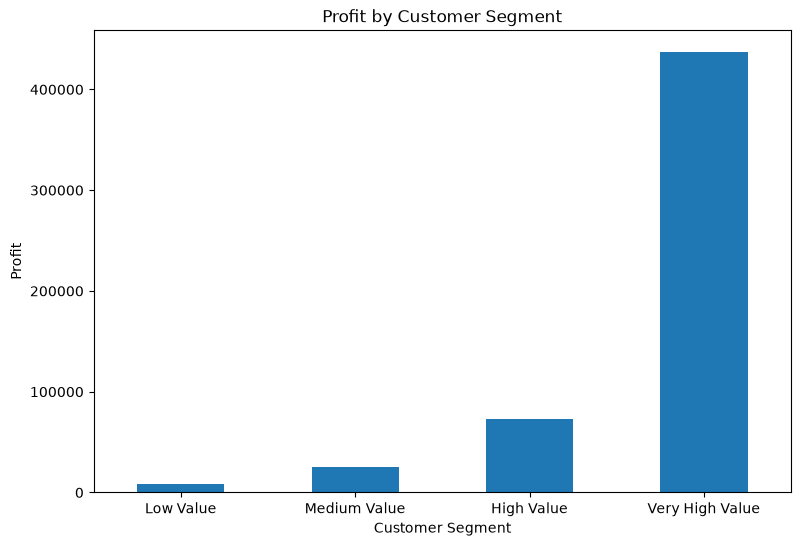

In [286]:
plt.figure(figsize=(9, 6))

segment_performance["Profit"].plot(kind="bar")

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")

plt.xticks(rotation=0)

plt.show()

### 8.9.5 Customer Segment Summary

In [287]:
segment_performance["AverageRevenuePerCustomer"] = (
    segment_performance["Revenue"] /
    segment_performance["Customers"]
)

segment_performance["AverageOrdersPerCustomer"] = (
    segment_performance["Orders"] /
    segment_performance["Customers"]
)

segment_performance.round(2)

,Customers,Revenue,Profit,Orders,Quantity,AverageRevenuePerCustomer,AverageOrdersPerCustomer
CustomerSegment,,,,,,,
Low Value,300,19941,8179,289,883,66.47,0.96
Medium Value,300,63881,25267,397,1622,212.94,1.32
High Value,304,191151,72548,499,2208,628.79,1.64
Very High Value,296,1247538,436635,515,2342,4214.66,1.74


### Customer Segmentation Summary

Customers are segmented based on their total revenue contribution. The analysis compares customer count, revenue, profit, orders, quantity, and average customer value across the segments.

## 8.10 KPI Dashboard Preparation

### 8.10.1 Overall Business KPIs

In [288]:
total_revenue = df["Revenue"].sum()
total_cost = df["TotalCost"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

total_customers = df["CustomerID"].nunique()
total_orders = df["OrderFlag"].sum()
total_returns = df["ReturnFlag"].sum()

average_order_value = total_revenue / total_orders
profit_margin = (total_profit / total_revenue) * 100
conversion_rate = (total_orders / len(df)) * 100
return_rate = (total_returns / total_orders) * 100

print("Total Revenue:", round(total_revenue, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity:", total_quantity)
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Returns:", int(total_returns))
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")
print("Conversion Rate:", round(conversion_rate, 2), "%")
print("Return Rate:", round(return_rate, 2), "%")

Total Revenue: 1522511
Total Cost: 979882
Total Profit: 542629
Total Quantity: 7055
Total Customers: 1200
Total Orders: 1700
Total Returns: 236
Average Order Value: 895.59
Profit Margin: 35.64 %
Conversion Rate: 85.0 %
Return Rate: 13.88 %


### 8.10.2 KPI Summary Table

In [289]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Total Quantity",
        "Total Customers",
        "Total Orders",
        "Total Returns",
        "Average Order Value",
        "Profit Margin (%)",
        "Conversion Rate (%)",
        "Return Rate (%)"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_profit,
        total_quantity,
        total_customers,
        total_orders,
        total_returns,
        average_order_value,
        profit_margin,
        conversion_rate,
        return_rate
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,1.522511e+06
1,Total Cost,9.798820e+05
2,Total Profit,5.426290e+05
3,Total Quantity,7.055000e+03
4,Total Customers,1.200000e+03
5,Total Orders,1.700000e+03
6,Total Returns,2.360000e+02
7,Average Order Value,8.955947e+02
8,Profit Margin (%),3.564040e+01
9,Conversion Rate (%),8.500000e+01


### 8.10.3 Revenue, Profit and Cost Comparison

In [290]:
financial_summary = pd.Series({
    "Revenue": total_revenue,
    "Cost": total_cost,
    "Profit": total_profit
})

financial_summary

Revenue    1522511
Cost        979882
Profit      542629
dtype: int64

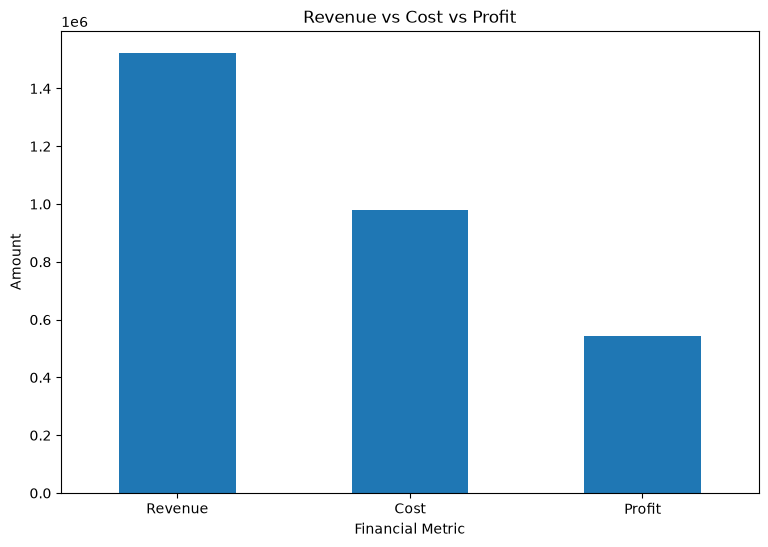

In [291]:
plt.figure(figsize=(9, 6))

financial_summary.plot(kind="bar")

plt.title("Revenue vs Cost vs Profit")
plt.xlabel("Financial Metric")
plt.ylabel("Amount")

plt.xticks(rotation=0)

plt.show()

### 8.10.4 Key Business Metrics for Power BI

The following metrics will be used as KPI cards and visualizations in the Power BI dashboard:

- Total Revenue
- Total Profit
- Total Orders
- Total Customers
- Total Quantity
- Average Order Value
- Profit Margin
- Conversion Rate
- Return Rate

## 8.11 EDA Conclusion

The exploratory data analysis examined customer demographics, sales performance, geographic distribution, customer journey, campaign performance, returns, payment methods, time-based trends, customer segmentation, and overall business KPIs.

The identified metrics and dimensions will be used in the SQL analysis and Power BI dashboard to provide a complete view of company performance.

## 9. Export Cleaned Dataset

### 9.1 Final Dataset Check

In [292]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 2000
Columns: 38
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   SessionStart            2000 non-null   datetime64[us]
 1   CustomerID              2000 non-null   int64         
 2   FullName                2000 non-null   str           
 3   Gender                  0 non-null      datetime64[s] 
 4   Age                     2000 non-null   int64         
 5   CreditScore             2000 non-null   int64         
 6   MonthlyIncome           2000 non-null   int64         
 7   Country                 2000 non-null   str           
 8   State                   2000 non-null   str           
 9   City                    2000 non-null   str           
 10  Category                2000 non-null   str           
 11  Product                 2000 non-null   str           
 12  Cost                    2000 non-nul

### 9.2 Check Missing Values

In [293]:
missing_summary = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing_summary[missing_summary > 0]

Gender                   2000
ReturnReason             1764
OrderConfirmationTime     300
PaymentMethod             300
OrderReturn               300
ReturnFlag                300
CartToOrderMinutes        300
dtype: int64

### 9.3 Export Cleaned Dataset

In [294]:
cleaned_file_path = "../data/company_data_cleaned.csv"

df.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset exported successfully!")
print("File:", cleaned_file_path)

Cleaned dataset exported successfully!
File: ../data/company_data_cleaned.csv


### 9.4 Verify Exported Dataset

In [295]:
import os

print("File exists:", os.path.exists(cleaned_file_path))
print("File size:", round(os.path.getsize(cleaned_file_path) / 1024, 2), "KB")

File exists: True
File size: 551.66 KB


## Python Phase Completed

The raw company dataset has been cleaned, transformed, analyzed, and exported as a cleaned CSV file. The cleaned dataset will now be used for SQL-based business analysis and Power BI visualization.

In [296]:
df_original = pd.read_csv("../data/Customer360Insights.csv")

In [297]:
df_original["Gender"].value_counts(dropna=False)

Gender
Female    1016
Male       984
Name: count, dtype: int64

In [298]:
df["Gender"].value_counts(dropna=False)

Gender
NaT    2000
Name: count, dtype: int64

In [299]:
df["Gender"] = df_original["Gender"]

In [300]:
print(df["Gender"].value_counts(dropna=False))

Gender
Female    1016
Male       984
Name: count, dtype: int64


In [301]:
df.to_csv("../data/company_data_cleaned.csv", index=False)

print("Cleaned CSV updated successfully!")

Cleaned CSV updated successfully!


In [302]:
check = pd.read_csv("../data/company_data_cleaned.csv")

print(check["Gender"].value_counts(dropna=False))

Gender
Female    1016
Male       984
Name: count, dtype: int64
